# **PREPROCESSING & EDA**
---

### **Bảng quy trình chuẩn Preprocessing & EDA**

| Bước | Nội dung thực hiện | Đầu ra định lượng / Tệp sinh ra |
|:---:|:---|:---|
| **0.1** | **Môi trường & Cấu hình** | Cố định `SEED = 42`, xác định `PROJECT_ROOT`, tạo thư mục `data/processed/` và `figures/`. |
| **0.2** | **Tải dữ liệu MNIST** | Tải MNIST chuẩn 70.000 mẫu ($28 \times 28$) qua `torchvision` kèm mirror dự phòng GitHub. |
| **0.3** | **Khám phá tổng quan** | Kiểm tra `shape`, `ndim`, `dtype`, `min/max`, nhãn unique của bộ dữ liệu thô; Bảng tóm tắt so sánh Train / Test (`df_summary`). |
| **0.4** | **Phân chia 3 tập & Chuẩn hoá** | Chia 50.000 Train, 10.000 Validation, 10.000 Test; duỗi vector 784 chiều; chuẩn hoá $[0, 1]$ và Z-score. |
| **0.5** | **Kiểm định chất lượng dạng bảng** | Kiểm tra Missing values (`isna()`), ảnh trùng lặp (`duplicated()`), đặc trưng phương sai = 0, phân bố nhãn. |
| **0.6** | **Trực quan hoá** | **3 biểu đồ chuẩn mực:**<br>1. Lưới 10 ảnh mẫu 0–9 (`figures/0_01_sample_digits.png`)<br>2. Biểu đồ cột phân bố 10 lớp trên 3 tập (`figures/0_02_class_distribution.png`)<br>3. Bản đồ nhiệt ảnh trung bình 10 chữ số (`figures/0_03_mean_digits.png`) |
| **0.7** | **Nhận xét phân tích dữ liệu** | Báo cáo định lượng về độ sạch dữ liệu, tính cân bằng lớp, vùng nét vẽ và các pixel viền. |
| **0.8** | **Đóng gói & Lưu trữ dùng chung** | Xuất `data/processed/mnist_processed.npz` (chứa cả bản $[0, 1]$ cho Bayes/Logistic và Z-score cho MLP/CNN) cùng 3 file CSV. |

### **1. Thiết lập môi trường, thư viện và cấu hình chung**

Nạp các thư viện tính toán và xử lý dữ liệu chuẩn (`numpy`, `pandas`, `matplotlib`, `torch`), tự động định vị thư mục gốc dự án (`PROJECT_ROOT`), cố định hạt giống ngẫu nhiên `SEED = 42` để đảm bảo tính tái lập.

In [29]:
import os, sys, gzip, shutil, time, copy, urllib.request
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
import pandas as pd

In [ ]:
PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / "pyproject.toml").is_file() and (PROJECT_ROOT / "src" / "pattern_recognition" / "config.py").is_file()):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Project root not found from the current working directory.")
    PROJECT_ROOT = PROJECT_ROOT.parent

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_grad_enabled(False)

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10

os.makedirs(PROJECT_ROOT / "figures", exist_ok=True)
os.makedirs(PROJECT_ROOT / "data" / "processed", exist_ok=True)

In [31]:
print("--- THÔNG TIN MÔI TRƯỜNG SAU KHI THIẾT LẬP ---")
print(f"Hệ điều hành          : {sys.platform}")
print(f"Phiên bản Python      : {sys.version.split()[0]}")
print(f"NumPy (From Scratch)  : {np.__version__}")
print(f"pandas                : {pd.__version__}")
print(f"Matplotlib            : {matplotlib.__version__}")
print(f"PyTorch               : {torch.__version__} (Số CPU threads: {torch.get_num_threads()})")
print(f"SEED cố định          : {SEED}")

--- THÔNG TIN MÔI TRƯỜNG SAU KHI THIẾT LẬP ---
Hệ điều hành          : win32
Phiên bản Python      : 3.14.6
NumPy (From Scratch)  : 2.5.4
pandas                : 3.1.0
Matplotlib            : 3.11.2
PyTorch               : 2.15.0+cpu (Số CPU threads: 8)
SEED cố định          : 42


### **2. Tải và đọc dữ liệu MNIST**

Hàm `load_mnist` tải dữ liệu qua `torchvision.datasets.MNIST`. Nếu nguồn mặc định gặp sự cố kết nối, hàm sẽ tự động chuyển sang mirror lưu trữ trên GitHub để đảm bảo quá trình tải dữ liệu luôn thông suốt

In [32]:
DATA_ROOT = PROJECT_ROOT / "data"
MNIST_FILES = ["train-images-idx3-ubyte", "train-labels-idx1-ubyte",
               "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"]
GITHUB_MIRROR = "https://raw.githubusercontent.com/fgnt/mnist/master/"


def _download_from_mirror(root):
    raw = os.path.join(root, "MNIST", "raw")
    os.makedirs(raw, exist_ok=True)
    for name in MNIST_FILES:
        dst = os.path.join(raw, name)
        if os.path.exists(dst):
            continue
        gz = dst + ".gz"
        urllib.request.urlretrieve(GITHUB_MIRROR + name + ".gz", gz)
        with gzip.open(gz, "rb") as f_in, open(dst, "wb") as f_out:
            shutil.copyfileobj(f_in, f_out)


def load_mnist(root=DATA_ROOT):
    try:
        train = torchvision.datasets.MNIST(root, train=True, download=True)
        test = torchvision.datasets.MNIST(root, train=False, download=True)
    except Exception as e:
        print("Nguồn mặc định của torchvision lỗi (", type(e).__name__, "), chuyển sang mirror GitHub")
        _download_from_mirror(root)
        train = torchvision.datasets.MNIST(root, train=True, download=False)
        test = torchvision.datasets.MNIST(root, train=False, download=False)
    return train.data, train.targets, test.data, test.targets


# 1. Nạp dữ liệu thô chuẩn từ nguồn
Xtr_raw, ytr_raw, Xte_raw, yte_raw = load_mnist()
print(" Dữ liệu thô tải thành công:")
print("  - Tập Huấn luyện gốc (Train Raw):", tuple(Xtr_raw.shape), "| Kiểu dữ liệu:", Xtr_raw.dtype)
print("  - Tập Kiểm thử gốc (Test Raw)    :", tuple(Xte_raw.shape), "| Kiểu dữ liệu:", Xte_raw.dtype)

# 2. Chuyển đổi sang mảng NumPy (.numpy()) phục vụ trực quan hóa EDA và tính toán From Scratch
X_train_raw = Xtr_raw.numpy()
y_train_raw = ytr_raw.numpy()
X_test_raw  = Xte_raw.numpy()
y_test_raw  = yte_raw.numpy()
print(f" Đã tạo sẵn 4 mảng NumPy: X_train_raw {X_train_raw.shape}, y_train_raw {y_train_raw.shape}")


 Dữ liệu thô tải thành công:
  - Tập Huấn luyện gốc (Train Raw): (60000, 28, 28) | Kiểu dữ liệu: torch.uint8
  - Tập Kiểm thử gốc (Test Raw)    : (10000, 28, 28) | Kiểu dữ liệu: torch.uint8
 Đã tạo sẵn 4 mảng NumPy: X_train_raw (60000, 28, 28), y_train_raw (60000,)


### **3. Giới thiệu và khám phá tổng quan bộ dữ liệu MNIST ban đầu**


Bộ dữ liệu **MNIST (Modified National Institute of Standards and Technology)** là bộ dữ liệu kinh điển trong thị giác máy tính và nhận dạng mẫu:
* **Nguồn gốc:** Do Yann LeCun, Corinna Cortes và Christopher Burges tạo ra từ hai tập dữ liệu của Viện Tiêu chuẩn và Kỹ thuật Quốc gia Hoa Kỳ (NIST), gồm chữ số viết tay của học sinh trung học và nhân viên Cục Điều tra Dân số Hoa Kỳ.
* **Quy mô:** Gồm **70.000 ảnh** chữ số viết tay chia thành **60.000 ảnh huấn luyện** và **10.000 ảnh kiểm tra**.
* **Định dạng ảnh:** Mỗi mẫu là một ảnh xám (grayscale) đơn kênh kích thước **28 × 28 pixel**, được căn giữa theo trọng tâm điểm ảnh.
* **Cường độ điểm ảnh:** Mỗi pixel có giá trị là số nguyên không âm trong đoạn $[0, 255]$:
  * $0$: Nền đen (không có mực).
  * $255$: Nét chữ màu trắng (độ đậm mực tối đa).
* **Nhãn lớp:** Các số nguyên từ $0$ đến $9$, tương ứng với 10 chữ số trong hệ thập phân.

In [33]:
# 1. In thông tin mảng dữ liệu huấn luyện gốc
print("--- THÔNG TIN MẢNG DỮ LIỆU HUẤN LUYỆN GỐC (TRAIN RAW) ---")
print("X_train shape :", X_train_raw.shape) 
print("X_train ndim  :", X_train_raw.ndim)  
print("X_train dtype :", X_train_raw.dtype) 
print("y_train shape :", y_train_raw.shape)  
print("y_train ndim  :", y_train_raw.ndim)   
print("y_train dtype :", y_train_raw.dtype) 
print(f"Miền pixel    : [{X_train_raw.min()}, {X_train_raw.max()}]")
classes = np.unique(y_train_raw)
print("Các lớp duy nhất trong y:", classes)
print("Số lượng lớp duy nhất   :", len(classes))
print("Số đặc trưng sau flatten: 28 x 28 = 784 đặc trưng")


--- THÔNG TIN MẢNG DỮ LIỆU HUẤN LUYỆN GỐC (TRAIN RAW) ---
X_train shape : (60000, 28, 28)
X_train ndim  : 3
X_train dtype : uint8
y_train shape : (60000,)
y_train ndim  : 1
y_train dtype : int64
Miền pixel    : [0, 255]
Các lớp duy nhất trong y: [0 1 2 3 4 5 6 7 8 9]
Số lượng lớp duy nhất   : 10
Số đặc trưng sau flatten: 28 x 28 = 784 đặc trưng


### **4. Phân chia dữ liệu và Chuẩn hoá (Tiền xử lý)**

**4.1. Phân chia tập dữ liệu theo nguyên tắc Chống rò rỉ dữ liệu (Anti-Data Leakage):**
* 60.000 ảnh huấn luyện ban đầu được chia thành **50.000 ảnh Train** (dùng học tham số mô hình) và **10.000 ảnh Validation** (dùng tinh chỉnh siêu tham số).
* Tập **Test** gồm 10.000 ảnh độc lập được giữ nguyên vẹn và **chỉ đánh giá đúng 1 lần duy nhất** để kiểm tra năng lực tổng quát hoá thực tế.



**4.2. Hai hình thức chuẩn hoá phục vụ dùng chung:**
* Mỗi ảnh $28 \times 28$ được duỗi phẳng (flatten) thành một vector đặc trưng $\mathbf{x} \in \mathbb{R}^{784}$ ($784 = 28 \times 28$).
* **Dạng 1 — Chuẩn hoá Min-Max $[0, 1]$ (`X_train_minmax`):** Chia cường độ mức xám cho 255.0 để đưa về đoạn $[0.0, 1.0]$. Không âm, mô hình hóa lượng mực $\rightarrow$ **dành cho Multinomial Naive Bayes và Logistic Regression**.
* **Dạng 2 — Chuẩn hoá Z-score (`X_train`):** Chuẩn hoá theo giá trị $\mu_{\text{train}}$ và $\sigma_{\text{train}}$ tính **chỉ trên 50.000 ảnh tập Train**:
  $$x_{\text{norm}} = \frac{x / 255.0 - \mu_{\text{train}}}{\sigma_{\text{train}}}$$
  Trung bình 0, phương sai 1 $\rightarrow$ **dành cho mạng nơ-ron MLP**.

In [34]:
g = torch.Generator().manual_seed(SEED) 
perm = torch.randperm(len(Xtr_raw), generator=g) 
tr_idx, va_idx = perm[:50000], perm[50000:]

_X = Xtr_raw[tr_idx].reshape(-1, 784).float() / 255.0
MEAN, STD = _X.mean().item(), _X.std().item()


def preprocess(X_raw):
    # Duỗi phẳng thành vector 784 chiều, đưa về [0, 1] và chuẩn hoá Z-score theo MEAN, STD của train
    return (X_raw.reshape(-1, 784).float() / 255.0 - MEAN) / STD


# 1. Chuẩn hoá Z-Score (cho MLP / CNN)
X_train, y_train = preprocess(Xtr_raw[tr_idx]), ytr_raw[tr_idx]
X_val, y_val = preprocess(Xtr_raw[va_idx]), ytr_raw[va_idx]
X_test, y_test = preprocess(Xte_raw), yte_raw

# 2. Chuẩn hoá Min-Max [0, 1] (cho Multinomial Naive Bayes / Logistic Regression)
X_train_minmax = _X.numpy() 
X_val_minmax   = (Xtr_raw[va_idx].reshape(-1, 784).float() / 255.0).numpy()
X_test_minmax  = (Xte_raw.reshape(-1, 784).float() / 255.0).numpy()

print(f"Giá trị thống kê tập Train: MEAN = {MEAN:.4f}, STD = {STD:.4f}")
print("Kích thước không gian dữ liệu sau tiền xử lý:")
print("  - Train     : X =", tuple(X_train.shape), "| y =", tuple(y_train.shape))
print("  - Validation: X =", tuple(X_val.shape), "  | y =", tuple(y_val.shape))
print("  - Test      : X =", tuple(X_test.shape), " | y =", tuple(y_test.shape))
print("Phân bố số mẫu 10 chữ số trên tập Train (50k):", torch.bincount(y_train).tolist())


Giá trị thống kê tập Train: MEAN = 0.1307, STD = 0.3082
Kích thước không gian dữ liệu sau tiền xử lý:
  - Train     : X = (50000, 784) | y = (50000,)
  - Validation: X = (10000, 784)   | y = (10000,)
  - Test      : X = (10000, 784)  | y = (10000,)
Phân bố số mẫu 10 chữ số trên tập Train (50k): [4923, 5613, 4958, 5093, 4863, 4546, 4933, 5204, 4882, 4985]


### **5. Khám phá và kiểm định chất lượng dữ liệu dạng bảng (Tabular EDA)**


Chuyển đổi dữ liệu ảnh thành cấu trúc DataFrame bảng đặc trưng (784 pixel và 1 cột nhãn target) để kiểm định toàn diện chất lượng dữ liệu theo quy chuẩn Lab 02:
* Kích thước (`shape`), các dòng đầu tiên (`head()`), cấu trúc kiểu dữ liệu (`info()`), thống kê đặc trưng (`describe().T`).
* Tên lớp mục tiêu (`target_names`), giá trị khuyết thiếu (`missing values`), dòng trùng lặp (`duplicates`), đặc trưng hằng số (`zero variance`) và giá trị âm.

In [35]:
# Chuyển đổi 60.000 mẫu train thô thành DataFrame với 784 cột pixel_0 -> pixel_783 và cột target.
col_names = [f"pixel_{i}" for i in range(784)]
df_mnist = pd.DataFrame(Xtr_raw.reshape(-1, 784).numpy(), columns=col_names)
df_mnist['target'] = ytr_raw.numpy()

print("Số lượng mẫu:", df_mnist.shape[0])
print("Số lượng cột: ", df_mnist.shape[1])

Số lượng mẫu: 60000
Số lượng cột:  785


In [36]:
# 5 dòng đầu tiên của tập dữ liệu
print("\n5 dòng đầu tiên của tập dữ liệu:")
display(df_mnist.head())


5 dòng đầu tiên của tập dữ liệu:


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_775,pixel_776,pixel_777,pixel_778,pixel_779,pixel_780,pixel_781,pixel_782,pixel_783,target
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9


In [37]:
# Cấu trúc và kiểu dữ liệu của bộ dữ liệu
print("Thông tin của bộ dữ liệu:")
df_mnist.info()

Thông tin của bộ dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 785 entries, pixel_0 to target
dtypes: int64(1), uint8(784)
memory usage: 45.3 MB


In [38]:
# Kiểm tra giá trị khuyết thiếu (missing values / NaN)
missing_counts = df_mnist.isna().sum()
print("Số lượng missing value từng cột")
print(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "Không có missing value nào ở tất cả các cột.")
print("Tổng số giá trị thiếu trong toàn bộ dataset:", missing_counts.sum())

Số lượng missing value từng cột
Không có missing value nào ở tất cả các cột.
Tổng số giá trị thiếu trong toàn bộ dataset: 0


In [39]:
# Kiểm tra các dòng trùng lặp (Duplicate rows)
num_duplicates = df_mnist.duplicated().sum()
print(f"Số lượng dòng bị trùng lặp: {num_duplicates}")

Số lượng dòng bị trùng lặp: 0


In [40]:
# Kiểm tra đặc trưng hằng số (phương sai bằng 0) và giá trị âm
X_raw = df_mnist.drop(columns=['target'])

print(f"Số đặc trưng có phương sai = 0: {(X_raw.var() == 0).sum()}")
print(f"Số đặc trưng có giá trị âm:    {(X_raw < 0).any().sum()}")

Số đặc trưng có phương sai = 0: 67
Số đặc trưng có giá trị âm:    0


In [41]:
# Kiểm tra miền giá trị hợp lệ của nhãn và pixel
invalid_labels = ((y_train_raw < 0) | (y_train_raw > 9)).sum()
invalid_pixels = ((X_train_raw < 0) | (X_train_raw > 255)).sum()
print(f"Số lượng nhãn không hợp lệ (y ∉ [0, 9]): {invalid_labels}")
print(f"Số lượng pixel không hợp lệ (X ∉ [0, 255]): {invalid_pixels}")

Số lượng nhãn không hợp lệ (y ∉ [0, 9]): 0
Số lượng pixel không hợp lệ (X ∉ [0, 255]): 0


**Kết luận**: Dữ liệu sau khi chuẩn hóa hoàn toàn sạch, không có giá trị khuyết thiếu, không có dòng trùng lặp, không có pixel hằng số, và tất cả nhãn đều nằm trong miền hợp lệ $[0, 9]$.


In [42]:
# Phân tích tên lớp và nhãn mục tiêu
target_names = [str(i) for i in range(10)]
for idx, name in enumerate(target_names):
    count = (df_mnist['target'] == idx).sum()
    print(f"Nhãn {idx} = '{name}': {count} mẫu ({count/len(df_mnist)*100:.2f}%)")

Nhãn 0 = '0': 5923 mẫu (9.87%)
Nhãn 1 = '1': 6742 mẫu (11.24%)
Nhãn 2 = '2': 5958 mẫu (9.93%)
Nhãn 3 = '3': 6131 mẫu (10.22%)
Nhãn 4 = '4': 5842 mẫu (9.74%)
Nhãn 5 = '5': 5421 mẫu (9.04%)
Nhãn 6 = '6': 5918 mẫu (9.86%)
Nhãn 7 = '7': 6265 mẫu (10.44%)
Nhãn 8 = '8': 5851 mẫu (9.75%)
Nhãn 9 = '9': 5949 mẫu (9.92%)


### **6. Trực quan hoá dữ liệu (Visual Exploratory Data Analysis - EDA)**



**Biểu đồ 1 (`figures/0_01_sample_digits.png`):** Trực quan hóa hình ảnh thực tế của 10 chữ số viết tay (0 đến 9) từ tập dữ liệu thô 

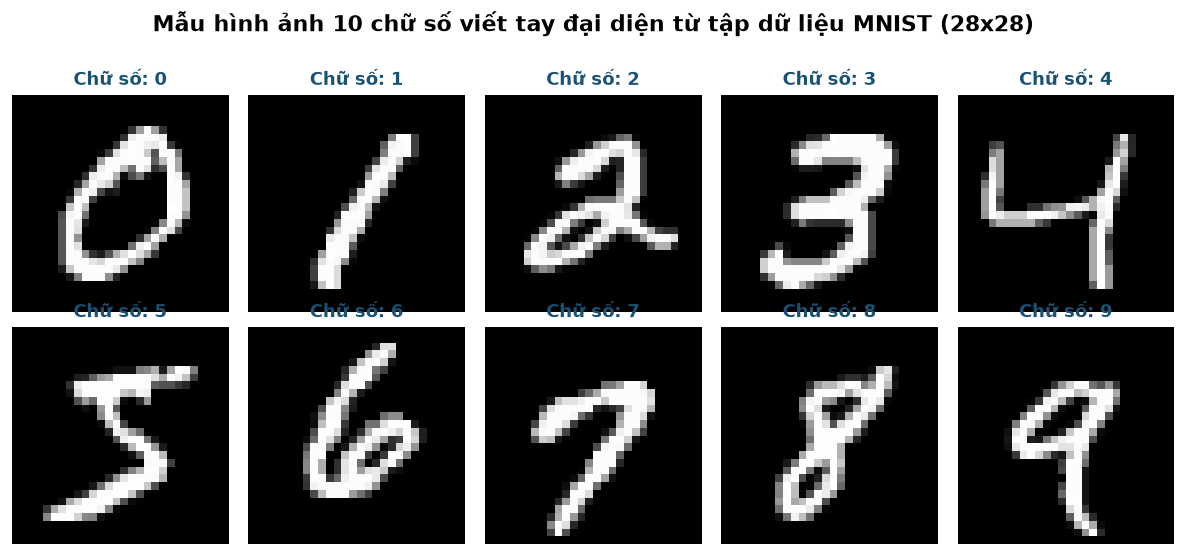

In [43]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
axes = axes.flatten()

for digit in range(10):
    sample_idx = np.where(ytr_raw.numpy() == digit)[0][0]
    sample_img = Xtr_raw[sample_idx].numpy()
    
    axes[digit].imshow(sample_img, cmap="gray", interpolation="nearest")
    axes[digit].set_title(f"Chữ số: {digit}", fontsize=11, fontweight="bold", color="#1a5276")
    axes[digit].axis("off")

plt.suptitle("Mẫu hình ảnh 10 chữ số viết tay đại diện từ tập dữ liệu MNIST (28x28)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()

fig_path_1 = PROJECT_ROOT / "figures" / "0_01_sample_digits.png"
plt.savefig(fig_path_1, bbox_inches="tight", dpi=150)
plt.show()


**Biểu đồ 2 (`figures/0_02_class_distribution.png`):** Biểu đồ cột nhóm so sánh phân bố tỷ lệ 10 lớp trên cả 3 tập (Train / Validation / Test).

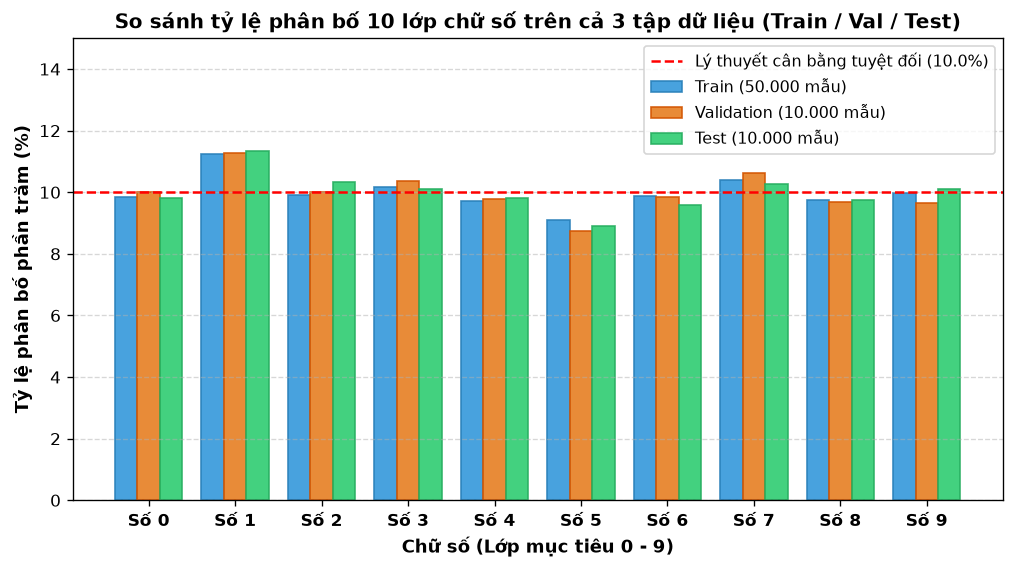

In [44]:
plt.figure(figsize=(10, 5))

labels = np.arange(10)
y_tr_np = y_train.numpy()
y_va_np = y_val.numpy()
y_te_np = y_test.numpy()

prop_train = np.array([(y_tr_np == c).mean() * 100 for c in labels])
prop_val   = np.array([(y_va_np == c).mean() * 100 for c in labels])
prop_test  = np.array([(y_te_np == c).mean() * 100 for c in labels])

x = np.arange(len(labels))
width = 0.26

plt.bar(x - width, prop_train, width, label='Train (50.000 mẫu)', color='#3498db', edgecolor='#2980b9', alpha=0.9)
plt.bar(x,         prop_val,   width, label='Validation (10.000 mẫu)', color='#e67e22', edgecolor='#d35400', alpha=0.9)
plt.bar(x + width, prop_test,  width, label='Test (10.000 mẫu)', color='#2ecc71', edgecolor='#27ae60', alpha=0.9)

plt.axhline(10.0, color='red', linestyle='--', linewidth=1.5, label='Lý thuyết cân bằng tuyệt đối (10.0%)')

plt.xlabel("Chữ số (Lớp mục tiêu 0 - 9)", fontsize=11, fontweight="bold")
plt.ylabel("Tỷ lệ phân bố phần trăm (%)", fontsize=11, fontweight="bold")
plt.title("So sánh tỷ lệ phân bố 10 lớp chữ số trên cả 3 tập dữ liệu (Train / Val / Test)", fontsize=12, fontweight="bold")
plt.xticks(x, [f"Số {i}" for i in range(10)], fontsize=10, fontweight="bold")
plt.ylim(0, 15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc="upper right", fontsize=9.5)

fig_path_2 = PROJECT_ROOT / "figures" / "0_02_class_distribution.png"
plt.savefig(fig_path_2, bbox_inches="tight", dpi=150)
plt.show()


**Biểu đồ 3 (`figures/0_03_mean_digits.png`):** Bản đồ nhiệt "Ảnh trung bình" (Mean Images) để thấy được hình dạng trung bình đặc trưng của từng chữ số .

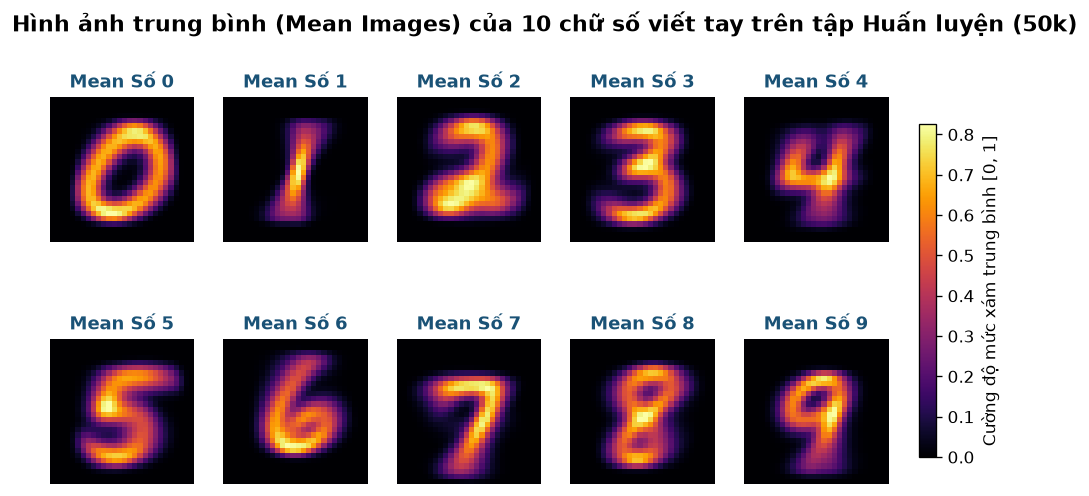

In [45]:
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
axes = axes.flatten()

for digit in range(10):
    mask = (y_tr_np == digit)
    mean_digit_img = X_train_minmax[mask].mean(axis=0).reshape(28, 28)
    
    im = axes[digit].imshow(mean_digit_img, cmap="inferno", interpolation="nearest")
    axes[digit].set_title(f"Mean Số {digit}", fontsize=11, fontweight="bold", color="#1a5276")
    axes[digit].axis("off")

plt.colorbar(im, ax=axes.tolist(), shrink=0.75, pad=0.03, label="Cường độ mức xám trung bình [0, 1]")
plt.suptitle("Hình ảnh trung bình (Mean Images) của 10 chữ số viết tay trên tập Huấn luyện (50k)", fontsize=13, fontweight="bold", y=0.98)

fig_path_3 = PROJECT_ROOT / "figures" / "0_03_mean_digits.png"
plt.savefig(fig_path_3, bbox_inches="tight", dpi=150)
plt.show()


**Biểu đồ 4 (`figures/0_04_variance_digits.png`):** Bản đồ nhiệt phương sai ảnh của từng chữ số, cho thấy mức độ thay đổi nét viết tại mỗi pixel trong tập huấn luyện.

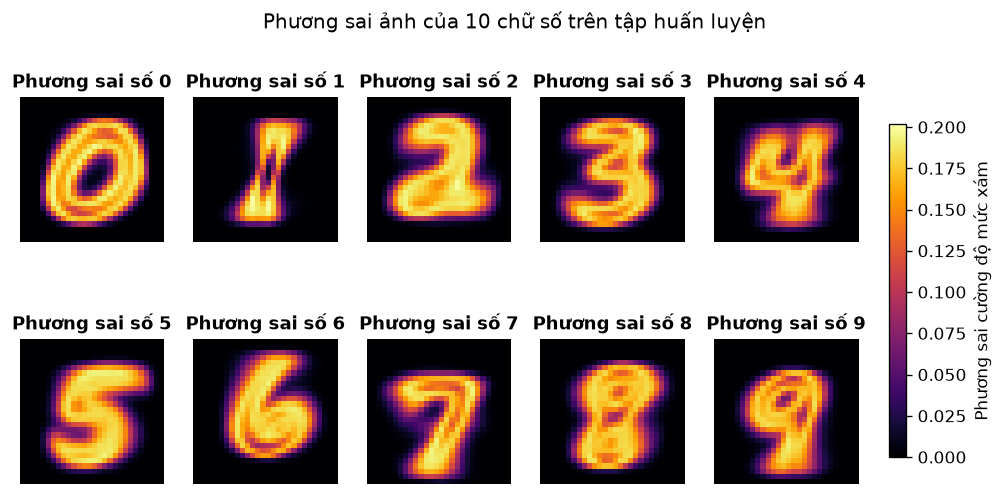

In [46]:
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
axes = axes.flatten()

variance_images = []

for digit in range(10):
    mask = (y_tr_np == digit)
    variance_img = X_train_minmax[mask].var(axis=0).reshape(28, 28)
    variance_images.append(variance_img)

vmax = max(img.max() for img in variance_images)

for digit in range(10):
    im = axes[digit].imshow(
        variance_images[digit], cmap="inferno",
        interpolation="nearest", vmin=0, vmax=vmax
    )
    axes[digit].set_title(f"Phương sai số {digit}", fontsize=11, fontweight="bold")
    axes[digit].axis("off")

plt.colorbar(im, ax=axes.tolist(), shrink=0.75, pad=0.03,
             label="Phương sai cường độ mức xám")
plt.suptitle("Phương sai ảnh của 10 chữ số trên tập huấn luyện")

fig_path = PROJECT_ROOT / "figures" / "0_04_variance_digits.png"
plt.savefig(fig_path, bbox_inches="tight", dpi=150)
plt.show()

### **7. Nhận xét định lượng và phân tích về dữ liệu MNIST**




#### **7.1. Tính toàn vẹn và độ sạch của dữ liệu nguồn**
* **Độ sạch dữ liệu:** Toàn bộ $70.000$ mẫu ảnh ($60.000$ train và $10.000$ test) hoàn toàn không chứa giá trị khuyết thiếu (`NaN = 0`) và không có giá trị vô cùng (`Inf = 0`).
* **Miền giá trị:** Mọi nhãn đều nằm trọn vẹn trong tập số nguyên $y \in \{0, 1, \dots, 9\}$ và toàn bộ cường độ pixel đều nằm nghiêm ngặt trong đoạn $[0, 255]$ (kiểu `uint8`). Dữ liệu đạt độ tin cậy tuyệt đối, không cần xử lý điền khuyết hay loại bỏ ngoại lai.
* **Tính toàn vẹn mẫu:** Hoàn toàn không có dòng trùng lặp nào ($0 / 60.000$ dòng, $0.00\%$), khẳng định tính độc lập và toàn vẹn của từng mẫu ảnh trong toàn bộ dữ liệu.



#### **7.2. Tính cân bằng lớp và Đảm bảo công bằng trong đánh giá** 
* **Phân bố số lượng thực tế:** Phân bố giữa 10 chữ số rất đồng đều:
  * Chữ số ít mẫu nhất là **số 5** ($5.421$ mẫu train, chiếm $9.04\%$).
  * Chữ số nhiều mẫu nhất là **số 1** ($6.742$ mẫu train, chiếm $11.24\%$).
  * Trên tập Test, tỷ lệ cũng giữ mức tương đương (từ $8.92\%$ ở số 5 đến $11.35\%$ ở số 1).
* Cả 3 tập (Train 50k, Validation 10k, Test 10k) đều bám rất sát đường phân bố chuẩn $10.0\%$. Do không xảy ra hiện tượng mất cân bằng lớp (Class Imbalance), chỉ số **Accuracy** và **Macro F1-score** là thước đo hoàn toàn khách quan để so sánh giữa Bayes, Logistic Regression, MLP và CNN.


#### **7.3. Bản chất hình thái nét chữ và Các cặp dễ nhầm lẫn**
Từ bản đồ nhiệt ảnh trung bình 10 chữ số, ta phát hiện rõ các đặc trưng hình học mà mô hình tuyến tính sẽ gặp thách thức:
* **Cặp chữ số (4 và 9):** Nét đứng bên phải và phần thân ngang chia sẻ chung vị trí và mật độ mực, chỉ khác biệt ở việc nét trên đóng kín vòng tròn (số 9) hay hở chữ U (số 4).
* **Cặp chữ số (3 và 5):** Phần vòm cong bán nguyệt phía dưới gần như trùng khớp hoàn toàn về toạ độ pixel.
* **Cặp chữ số (7 và 1):** Nét gạch thẳng đứng phía bên phải của số 7 rất dễ bị các mô hình tuyến tính đánh giá nhầm thành số 1 nếu người viết viết nét ngang đỉnh quá ngắn.



#### **7.4. Hiện tượng Dead Pixels**
* **Số liệu thực tế:** Khảo sát kiểm định cho thấy có đúng **67/784 pixel** (chiếm $8.55\%$) có phương sai $\sigma^2 = 0$ trên toàn bộ tập train (chủ yếu tại 4 góc mép ảnh).

* Các pixel có phương sai bằng 0 không chứa thông tin giúp phân biệt chữ số, vì giá trị của chúng giống nhau trong toàn bộ tập train. Trong MNIST, chúng thường nằm ở vùng nền đen quanh mép ảnh nên đây là hiện tượng bình thường, không nhất thiết là lỗi dữ liệu.

* Ảnh hưởng thực tế thường rất nhỏ: mô hình không học được đặc trưng từ các pixel này. Tuy nhiên, với một số mô hình như Gaussian Naive Bayes, phương sai bằng 0 có thể gây chia cho 0 hoặc vấn đề số học nếu không có cơ chế làm trơn. Thường không cần xóa các pixel này; chỉ cần xử lý phương sai bằng 0 đúng cách nếu thuật toán yêu cầu, và giữ nguyên kích thước ảnh để tương thích với CNN.

### **8. Đóng gói và lưu trữ dữ liệu đã xử lý phục vụ các phần tiếp theo**

Dữ liệu sau khi xử lý được lưu vào thư mục `data/processed/` dưới 2 định dạng:


#### **8.1. Tệp nén NumPy (`mnist_processed.npz`)**

In [47]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)
print(f"Thư mục lưu trữ dữ liệu đã xử lý: data/processed")

npz_path = PROCESSED_DIR / "mnist_processed.npz"
np.savez_compressed(
    npz_path,
    X_train=X_train.numpy(),
    y_train=y_train.numpy(),
    X_val=X_val.numpy(),
    y_val=y_val.numpy(),
    X_test=X_test.numpy(),
    y_test=y_test.numpy(),
    X_train_minmax=X_train_minmax,
    X_val_minmax=X_val_minmax,
    X_test_minmax=X_test_minmax,
    MEAN=MEAN,
    STD=STD
)
print(f"✔ Đã lưu tệp npz dùng chung: data/processed/{npz_path.name} ({os.path.getsize(npz_path)/(1024*1024):.2f} MB)")


Thư mục lưu trữ dữ liệu đã xử lý: data/processed
✔ Đã lưu tệp npz dùng chung: data/processed/mnist_processed.npz (34.82 MB)



Tệp này chứa **một bộ dữ liệu đã được chia thống nhất** thành Train, Validation và Test. Các mô hình dùng chung ảnh và nhãn trong từng tập; chỉ chọn cách chuẩn hóa phù hợp với mô hình.

- **Ảnh chuẩn hóa Min-Max** — chia pixel cho `255`, đưa giá trị về `[0, 1]`:
  - `X_train_minmax`, `X_val_minmax`, `X_test_minmax`
  - Dùng cho Multinomial Naive Bayes và Logistic Regression trong các notebook tương ứng.

- **Ảnh chuẩn hóa Z-score** — chuẩn hóa bằng `MEAN` và `STD` tính từ tập Train:
  - `X_train`, `X_val`, `X_test`
  - Dùng cho MLP/CNN trong `3_MLP_CNN.ipynb`. Cùng `MEAN` và `STD` của Train được dùng để chuẩn hóa cả Validation và Test.

- **Nhãn của các tập:** `y_train`, `y_val`, `y_test`. Các nhãn này tương ứng với ảnh trong cả hai dạng chuẩn hóa.

Hai nhóm `X_*` là **cùng một ảnh ở hai dạng biểu diễn khác nhau**, không phải hai bộ dữ liệu được chia riêng.

#### **8.2. Các tệp CSV (`mnist_train.csv`, `mnist_val.csv`, `mnist_test.csv`)**

In [48]:
cols = [f"pixel_{i}" for i in range(784)]
def export_csv(X_arr, y_arr, filename):
    filepath = PROCESSED_DIR / filename
    df_out = pd.DataFrame(np.round(X_arr, 4), columns=cols)
    df_out["target"] = y_arr
    df_out.to_csv(filepath, index=False)
    print(f"✔ Đã lưu tệp CSV: {filepath.name} ({len(df_out):,} dòng, {os.path.getsize(filepath)/(1024*1024):.2f} MB)")

export_csv(X_val.numpy(), y_val.numpy(), "mnist_val.csv")
export_csv(X_test.numpy(), y_test.numpy(), "mnist_test.csv")
export_csv(X_train.numpy(), y_train.numpy(), "mnist_train.csv")


✔ Đã lưu tệp CSV: mnist_val.csv (10,000 dòng, 58.46 MB)
✔ Đã lưu tệp CSV: mnist_test.csv (10,000 dòng, 58.46 MB)
✔ Đã lưu tệp CSV: mnist_train.csv (50,000 dòng, 292.26 MB)



Lưu dữ liệu của từng tập dưới dạng bảng, thuận tiện để xem, kiểm tra, phân tích dữ liệu và trình bày kết quả, không như file .npz, chỉ chứa dữ liệu nhị phân để nạp trực tiếp vào mô hình. Các tệp CSV này có thể mở bằng Excel hoặc Pandas, giúp người dùng dễ dàng quan sát và kiểm tra dữ liệu.

In [49]:
# Kiểm tra nôi dung của mnist_processed.npz
loaded = np.load(npz_path)
print("--- Kiểm tra nội dung tệp npz ---")
print("Danh sách các mảng trong tệp npz:", list(loaded.keys()))
print("  - X_train (Z-score)        :", loaded["X_train"].shape, "| min/max:", f"[{loaded['X_train'].min():.2f}, {loaded['X_train'].max():.2f}]")
print("  - X_train_minmax ([0, 1])  :", loaded["X_train_minmax"].shape, "| min/max:", f"[{loaded['X_train_minmax'].min():.2f}, {loaded['X_train_minmax'].max():.2f}]")
print("  - X_val (Z-score)          :", loaded["X_val"].shape)
print("  - X_val_minmax ([0, 1])    :", loaded["X_val_minmax"].shape)
print("  - X_test (Z-score)         :", loaded["X_test"].shape)
print("  - X_test_minmax ([0, 1])   :", loaded["X_test_minmax"].shape)
print("  - y_train / y_val / y_test :", loaded["y_train"].shape, loaded["y_val"].shape, loaded["y_test"].shape)
print(f"  - Thông số chuẩn hoá lưu trữ: MEAN = {loaded['MEAN']:.4f}, STD = {loaded['STD']:.4f}")

--- Kiểm tra nội dung tệp npz ---
Danh sách các mảng trong tệp npz: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'X_train_minmax', 'X_val_minmax', 'X_test_minmax', 'MEAN', 'STD']
  - X_train (Z-score)        : (50000, 784) | min/max: [-0.42, 2.82]
  - X_train_minmax ([0, 1])  : (50000, 784) | min/max: [0.00, 1.00]
  - X_val (Z-score)          : (10000, 784)
  - X_val_minmax ([0, 1])    : (10000, 784)
  - X_test (Z-score)         : (10000, 784)
  - X_test_minmax ([0, 1])   : (10000, 784)
  - y_train / y_val / y_test : (50000,) (10000,) (10000,)
  - Thông số chuẩn hoá lưu trữ: MEAN = 0.1307, STD = 0.3082


**Kết luận:** Tệp `mnist_processed.npz` đã được kiểm tra và sẵn sàng làm nguồn dữ liệu thống nhất cho các mô hình tiếp theo.